ITEM 1.1: SES - Process Yield


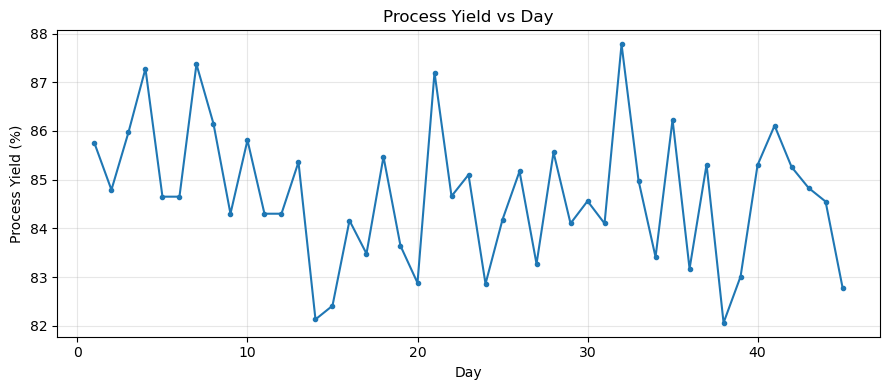

a) Plot saved. Check visually: series fluctuates around a constant mean with no trend -> stationary (constant process).

b) 1-step-ahead forecasts (Days 2-45):
 Day  Actual  F(a=0.20)  F(a=0.40)
   2   84.79    85.7500    85.7500
   3   85.97    85.5580    85.3660
   4   87.28    85.6404    85.6076
   5   84.65    85.9683    86.2766
   6   84.65    85.7047    85.6259
   7   87.37    85.4937    85.2356
   8   86.15    85.8690    86.0893
   9   84.30    85.9252    86.1136
  10   85.81    85.6001    85.3882
  11   84.30    85.6421    85.5569
  12   84.30    85.3737    85.0541
  13   85.36    85.1590    84.7525
  14   82.13    85.1992    84.9955
  15   82.41    84.5853    83.8493
  16   84.16    84.1503    83.2736
  17   83.48    84.1522    83.6281
  18   85.47    84.0178    83.5689
  19   83.64    84.3082    84.3293
  20   82.88    84.1746    84.0536
  21   87.20    83.9157    83.5842
  22   84.66    84.5725    85.0305
  23   85.10    84.5900    84.8823
  24   82.86    84.6920    84.9694


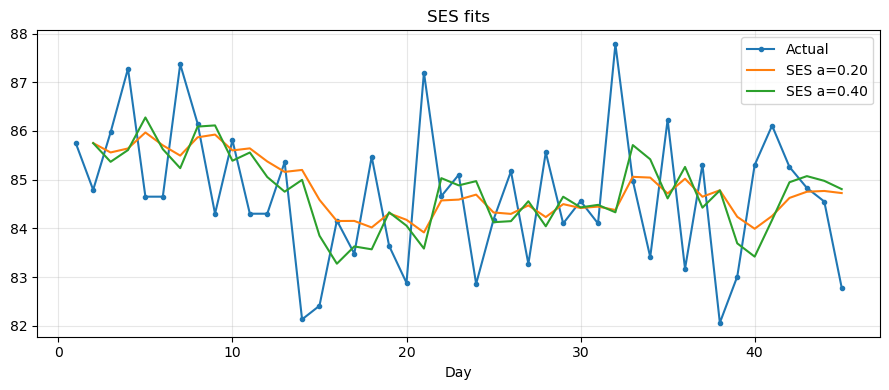


ITEM 1.2: Holt's - Medical Sales


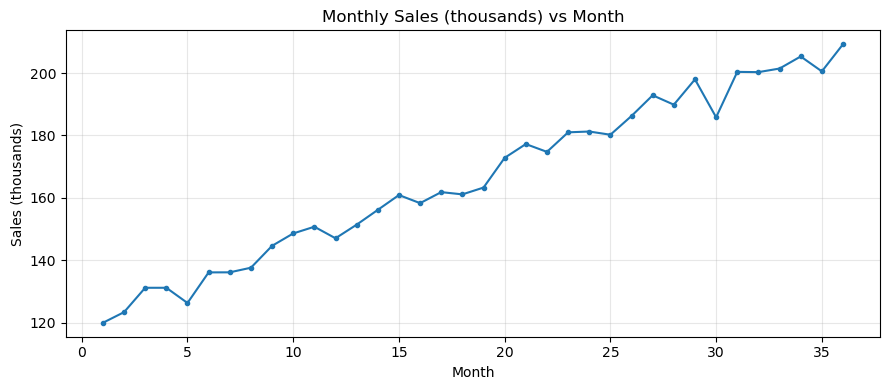

a) Plot saved. Sales show a clear upward linear trend. SES assumes a constant level (forecast is a flat line), so it lags persistently behind a trending series and yields biased (under-)forecasts. Holt's method adds a trend component T_t, so forecasts can project the slope: F_{T+tau} = L_T + tau*T_T.

b) Holt's (alpha=0.3, beta=0.2) level & trend:
 Month  Sales    Level  Trend
     1 119.98 119.9800 3.4100
     2 123.39 123.3900 3.4100
     3 131.20 128.1200 3.6740
     4 131.20 131.6158 3.6384
     5 126.33 132.5769 3.1029
     6 136.13 135.8149 3.1299
     7 136.15 138.1064 2.9622
     8 137.63 140.0370 2.7559
     9 144.64 143.3471 2.8667
    10 148.61 146.9327 3.0105
    11 150.76 150.1882 3.0595
    12 147.06 151.3914 2.6883
    13 151.42 153.2818 2.5287
    14 156.16 155.9153 2.5497
    15 160.91 159.1985 2.6964
    16 158.32 160.8224 2.4819
    17 161.85 162.8680 2.3946
    18 161.13 164.0228 2.1467
    19 163.31 165.3116 1.9751
    20 172.84 168.9527 2.3083
    21 177.25 173.05

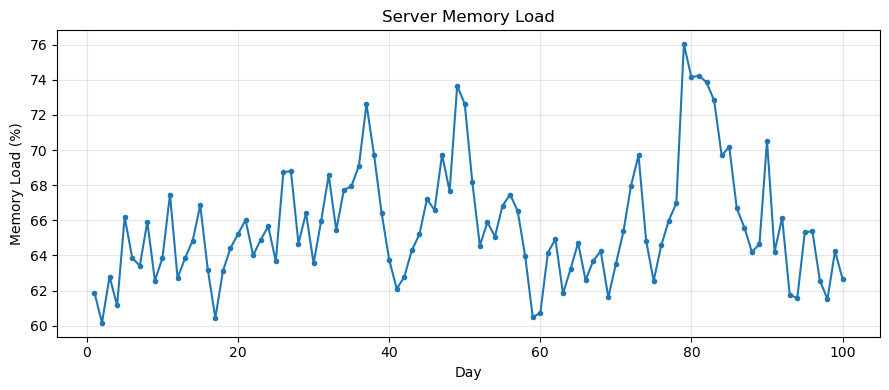

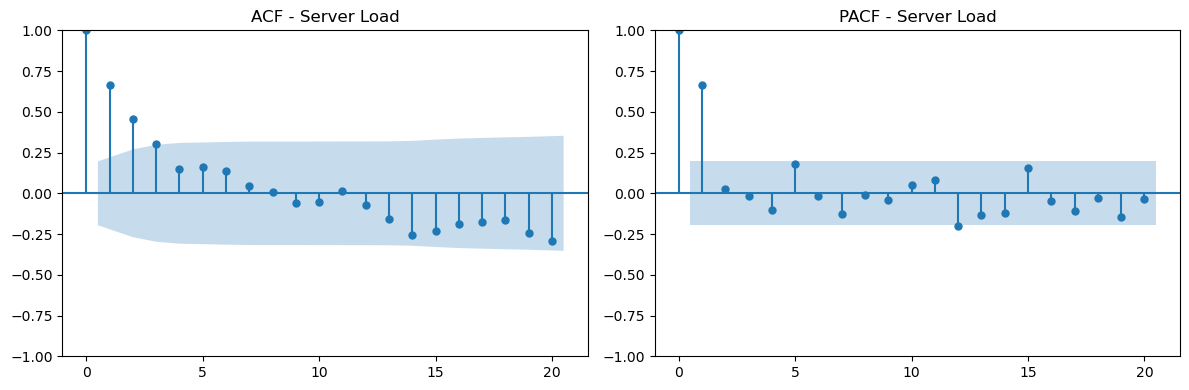

a) Plots saved (plots/2_1a_*.png).
b) Identification: ACF decays gradually (tails off) while PACF has one significant spike at lag 1 and cuts off afterwards -> AR(1). Tentative model: ARIMA(1,0,0).

c) Fitted ARIMA(1,0,0):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         65.5628      0.813     80.633      0.000      63.969      67.156
ar.L1          0.6734      0.089      7.571      0.000       0.499       0.848
sigma2         6.1029      0.731      8.354      0.000       4.671       7.535
   Estimated parameters:
 const     65.5628
ar.L1      0.6734
sigma2     6.1029


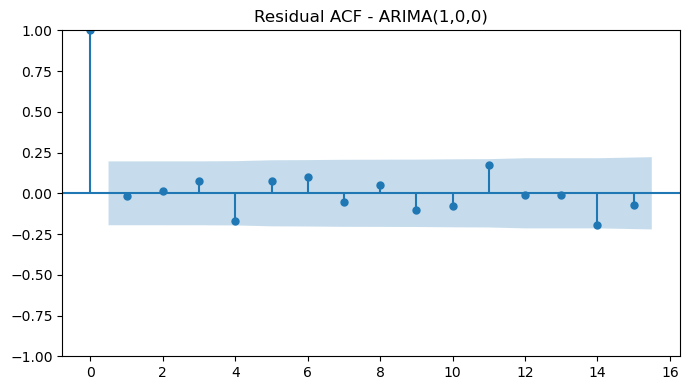


d) 95% limits = +/-0.1960
   Residual ACF lags 1-15: [-0.018  0.015  0.073 -0.17   0.079  0.099 -0.053  0.052 -0.101 -0.075
  0.175 -0.012 -0.011 -0.192 -0.069]
   Lags outside limits: none
   Ljung-Box:
     lb_stat  lb_pvalue
10   7.8106     0.5533
15  16.2701     0.2972
   Conclusion: residuals behave as white noise (model adequate).

e) Forecasts with 95% prediction intervals:
   h=1: 63.6081  [58.7663, 68.4500]
   h=2: 64.2466  [58.4093, 70.0839]

ITEM 2.2: ARIMA - Power Demand


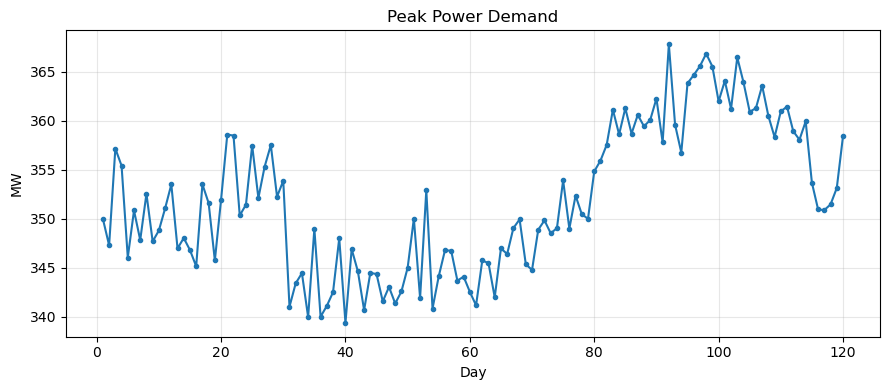

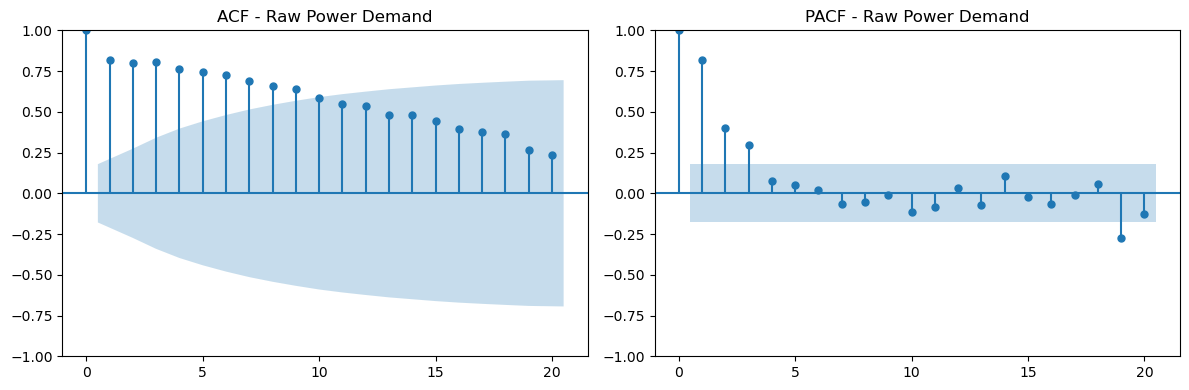

a) Raw ACF decays very slowly and almost linearly (stays large at many lags). For a stationary series ACF dies out quickly (exponentially); persistent high autocorrelation means shocks never die out, i.e. a stochastic trend/unit root -> non-stationary, differencing needed.

b) First difference computed, N = 119


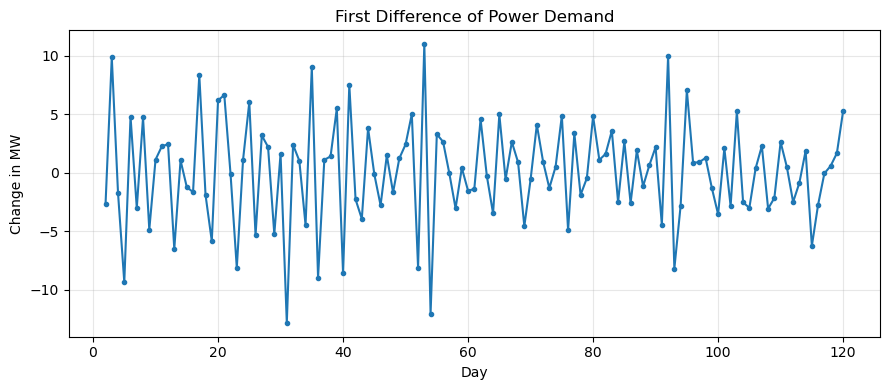

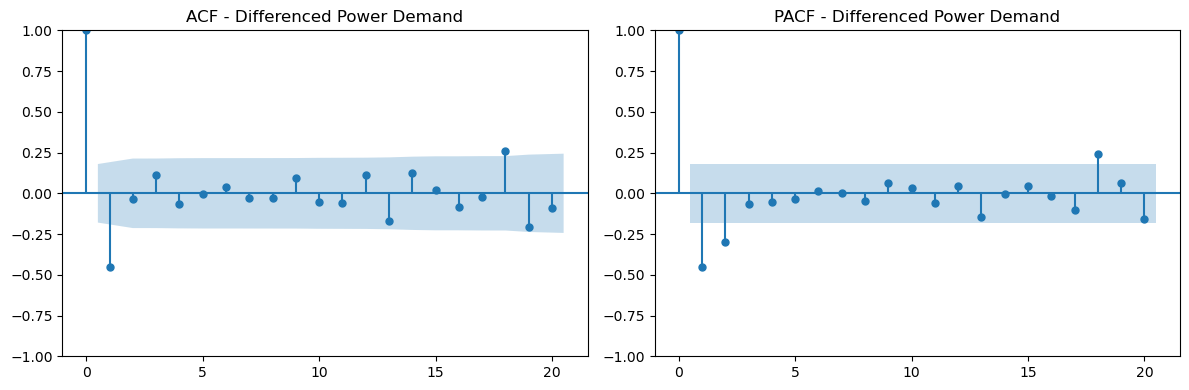

c) Differenced ACF has a single significant spike at lag 1 then cuts off; PACF tails off -> MA(1) on the differenced series. Tentative model: ARIMA(0,1,1).

d) Fitted ARIMA(0,1,1):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5884      0.069     -8.475      0.000      -0.724      -0.452
sigma2        14.1546      1.705      8.300      0.000      10.812      17.497
   Estimated parameters:
 ma.L1     -0.5884
sigma2    14.1546


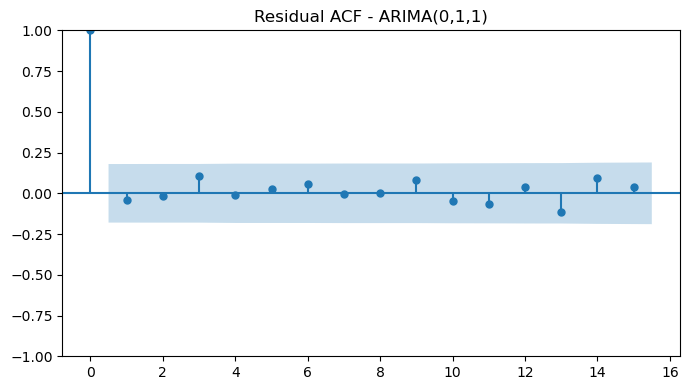


e) 95% limits = +/-0.1797
   Residual ACF lags 1-15: [-0.043 -0.014  0.105 -0.009  0.026  0.059 -0.002  0.005  0.082 -0.049
 -0.068  0.039 -0.115  0.095  0.039]
   Lags outside limits: none
   Ljung-Box:
     lb_stat  lb_pvalue
10   3.3439     0.9491
15   7.4257     0.9171
   Conclusion: residuals behave as white noise (model adequate).

   Forecasts with 95% prediction intervals:
   h=1: 355.0705  [347.6966, 362.4444]
   h=2: 355.0705  [347.0963, 363.0446]


In [ ]:
"""
APM1215 FA3 - Maria Elizabeth Abad
"""
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

DATA_DIR = "C:/Users/Elize/Documents/YR4 1st sem/TIME SERIES"
os.chdir(DATA_DIR)
os.makedirs("plots", exist_ok=True)


def ts_plot(x, y, title, xlabel, ylabel, fname):
    plt.figure(figsize=(9, 4))
    plt.plot(x, y, marker="o", ms=3)
    plt.title(title); plt.xlabel(xlabel); plt.ylabel(ylabel)
    plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(f"plots/{fname}.png", dpi=150); plt.show()


def acf_pacf_plot(series, lags, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    plot_acf(series, lags=lags, ax=ax[0], title=f"ACF - {title}")
    plot_pacf(series, lags=lags, ax=ax[1], method="ywm", title=f"PACF - {title}")
    plt.tight_layout(); plt.savefig(f"plots/{fname}.png", dpi=150); plt.show()


# =====================================================================
# ITEM 1.1  Simple Exponential Smoothing
# =====================================================================
print("=" * 70, "\nITEM 1.1: SES - Process Yield\n", "=" * 70, sep="")
df = pd.read_csv(f"{DATA_DIR}/ses-process-yield.csv")
y = df["Process_Yield"].values
n = len(y)

# a) time series plot
ts_plot(df["Day"], y, "Process Yield vs Day", "Day", "Process Yield (%)", "1_1a_yield")
print("a) Plot saved. Check visually: series fluctuates around a constant mean "
      "with no trend -> stationary (constant process).")


def ses(y, alpha):
    """F_1 = y_1; F_{t+1} = alpha*y_t + (1-alpha)*F_t. Returns F_1..F_{n+1}."""
    F = np.empty(len(y) + 1)
    F[0] = y[0]                       # initial forecast = first observation
    for t in range(len(y)):
        F[t + 1] = alpha * y[t] + (1 - alpha) * F[t]
    return F


results = {}
for a in (0.20, 0.40):
    F = ses(y, a)
    fc = F[1:n]                       # forecasts for Days 2..45
    act = y[1:]                       # actuals Days 2..45
    err = act - fc
    mse = np.mean(err ** 2)
    mape = np.mean(np.abs(err / act)) * 100
    results[a] = dict(F=F, mse=mse, mape=mape)

# b) forecasts table
tbl = pd.DataFrame({
    "Day": df["Day"].values[1:], "Actual": y[1:],
    "F(a=0.20)": results[0.20]["F"][1:n], "F(a=0.40)": results[0.40]["F"][1:n],
})
print("\nb) 1-step-ahead forecasts (Days 2-45):")
print(tbl.round(4).to_string(index=False))
tbl.to_csv("plots/1_1b_ses_forecasts.csv", index=False)

# c) accuracy
print("\nc) Accuracy (Days 2-45):")
for a in results:
    print(f"   alpha={a:.2f}: MSE={results[a]['mse']:.4f}  MAPE={results[a]['mape']:.4f}%")
best = min(results, key=lambda a: results[a]["mse"])
print(f"   -> Better in-sample fit: alpha = {best:.2f}")

# d) Day 46 forecast
print(f"\nd) Day 46 forecast (alpha={best:.2f}): {results[best]['F'][n]:.4f}")

plt.figure(figsize=(9, 4))
plt.plot(df["Day"], y, "o-", ms=3, label="Actual")
for a in results:
    plt.plot(df["Day"].values[1:], results[a]["F"][1:n], label=f"SES a={a:.2f}")
plt.legend(); plt.grid(alpha=.3); plt.title("SES fits"); plt.xlabel("Day")
plt.tight_layout(); plt.savefig("plots/1_1_ses_fit.png", dpi=150); plt.show()


# =====================================================================
# ITEM 1.2  Holt's Linear Exponential Smoothing
# =====================================================================
print("\n" + "=" * 70, "\nITEM 1.2: Holt's - Medical Sales\n", "=" * 70, sep="")
df = pd.read_csv(f"{DATA_DIR}/holts-medical-sales.csv")
y = df["Sales_Thousands"].values
n = len(y)

# a) plot
ts_plot(df["Month"], y, "Monthly Sales (thousands) vs Month", "Month",
        "Sales (thousands)", "1_2a_sales")
print("a) Plot saved. Sales show a clear upward linear trend. SES assumes a constant "
      "level (forecast is a flat line), so it lags persistently behind a trending "
      "series and yields biased (under-)forecasts. Holt's method adds a trend "
      "component T_t, so forecasts can project the slope: F_{T+tau} = L_T + tau*T_T.")

# b) Holt's recursion
alpha, beta = 0.30, 0.20
L = np.empty(n); T = np.empty(n)
L[0] = y[0]
T[0] = y[1] - y[0]
for t in range(1, n):
    L[t] = alpha * y[t] + (1 - alpha) * (L[t - 1] + T[t - 1])
    T[t] = beta * (L[t] - L[t - 1]) + (1 - beta) * T[t - 1]

holt = pd.DataFrame({"Month": df["Month"], "Sales": y, "Level": L, "Trend": T})
print(f"\nb) Holt's (alpha={alpha}, beta={beta}) level & trend:")
print(holt.round(4).to_string(index=False))
holt.to_csv("plots/1_2b_holt_components.csv", index=False)

# c) forecasts
print("\nc) Forecasts from origin T = 36:")
for tau in (1, 2):
    print(f"   Month {n + tau} (tau={tau}): {L[-1] + tau * T[-1]:.4f}")


# =====================================================================
# ITEM 2.1  Stationary ARIMA - Server Load
# =====================================================================
print("\n" + "=" * 70, "\nITEM 2.1: ARIMA - Server Memory Load\n", "=" * 70, sep="")
df = pd.read_csv(f"{DATA_DIR}/arima-server-load.csv")
y = df["Memory_Load_Pct"]

# a)
ts_plot(df["Day"], y, "Server Memory Load", "Day", "Memory Load (%)", "2_1a_series")
acf_pacf_plot(y, 20, "Server Load", "2_1a_acf_pacf")
print("a) Plots saved (plots/2_1a_*.png).")

# b) identification
print("b) Identification: ACF decays gradually (tails off) while PACF has one "
      "significant spike at lag 1 and cuts off afterwards -> AR(1). "
      "Tentative model: ARIMA(1,0,0).")
p, d, q = 1, 0, 0   # <- change if your own plots suggest otherwise

# c) estimation
fit = ARIMA(y, order=(p, d, q), trend="c").fit()
print(f"\nc) Fitted ARIMA({p},{d},{q}):")
print(fit.summary().tables[1])
print("   Estimated parameters:\n", fit.params.round(4).to_string())

# d) residual diagnostics
resid = fit.resid
fig, ax = plt.subplots(figsize=(7, 4))
plot_acf(resid, lags=15, ax=ax, title="Residual ACF - ARIMA(1,0,0)")
plt.tight_layout(); plt.savefig("plots/2_1d_resid_acf.png", dpi=150); plt.show()
from statsmodels.tsa.stattools import acf as _acf
r = _acf(resid, nlags=15)[1:]
lim = 1.96 / np.sqrt(len(resid))
out = np.where(np.abs(r) > lim)[0] + 1
print(f"\nd) 95% limits = +/-{lim:.4f}")
print("   Residual ACF lags 1-15:", np.round(r, 3))
print("   Lags outside limits:", list(out) if len(out) else "none")
from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(resid, lags=[10, 15], model_df=p + q)
print("   Ljung-Box:\n", lb.round(4))
print("   Conclusion:", "residuals behave as white noise (model adequate)."
      if len(out) == 0 else
      "some residual autocorrelations exceed the limits - see note above; "
      "consider refining the model.")

# e) forecasts
fc = fit.get_forecast(2)
m = fc.predicted_mean
ci = fc.conf_int(alpha=0.05)
print("\ne) Forecasts with 95% prediction intervals:")
for h in range(2):
    print(f"   h={h + 1}: {m.iloc[h]:.4f}  [{ci.iloc[h, 0]:.4f}, {ci.iloc[h, 1]:.4f}]")


# =====================================================================
# ITEM 2.2  Non-stationary ARIMA - Power Demand
# =====================================================================
print("\n" + "=" * 70, "\nITEM 2.2: ARIMA - Power Demand\n", "=" * 70, sep="")
df = pd.read_csv(f"{DATA_DIR}/arima-power-demand.csv")
y = df["Power_Demand_MW"]

# a) raw
ts_plot(df["Day"], y, "Peak Power Demand", "Day", "MW", "2_2a_series")
acf_pacf_plot(y, 20, "Raw Power Demand", "2_2a_acf_pacf")
print("a) Raw ACF decays very slowly and almost linearly (stays large at many "
      "lags). For a stationary series ACF dies out quickly (exponentially); "
      "persistent high autocorrelation means shocks never die out, i.e. a "
      "stochastic trend/unit root -> non-stationary, differencing needed.")

# b) first difference
dy = y.diff().dropna()
print(f"\nb) First difference computed, N = {len(dy)}")
ts_plot(df["Day"].values[1:], dy, "First Difference of Power Demand", "Day",
        "Change in MW", "2_2b_diff")

# c) differenced ACF/PACF
acf_pacf_plot(dy, 20, "Differenced Power Demand", "2_2c_acf_pacf")
print("c) Differenced ACF has a single significant spike at lag 1 then cuts off; "
      "PACF tails off -> MA(1) on the differenced series. "
      "Tentative model: ARIMA(0,1,1).")
p, d, q = 0, 1, 1   # <- change if your own plots suggest otherwise

# d) estimation (no constant for d=1 by default; add trend="t" for drift)
fit = ARIMA(y, order=(p, d, q)).fit()
print(f"\nd) Fitted ARIMA({p},{d},{q}):")
print(fit.summary().tables[1])
print("   Estimated parameters:\n", fit.params.round(4).to_string())

# e) diagnostics + forecasts
resid = fit.resid.iloc[d:]          
fig, ax = plt.subplots(figsize=(7, 4))
plot_acf(resid, lags=15, ax=ax, title="Residual ACF - ARIMA(0,1,1)")
plt.tight_layout(); plt.savefig("plots/2_2e_resid_acf.png", dpi=150); plt.show()
r = _acf(resid, nlags=15)[1:]
lim = 1.96 / np.sqrt(len(resid))
out = np.where(np.abs(r) > lim)[0] + 1
print(f"\ne) 95% limits = +/-{lim:.4f}")
print("   Residual ACF lags 1-15:", np.round(r, 3))
print("   Lags outside limits:", list(out) if len(out) else "none")
lb = acorr_ljungbox(resid, lags=[10, 15], model_df=p + q)
print("   Ljung-Box:\n", lb.round(4))
print("   Conclusion:", "residuals behave as white noise (model adequate)."
      if len(out) == 0 else
      "some residual autocorrelations exceed the limits - see note above.")

fc = fit.get_forecast(2)
m = fc.predicted_mean
ci = fc.conf_int(alpha=0.05)
print("\n   Forecasts with 95% prediction intervals:")
for h in range(2):
    print(f"   h={h + 1}: {m.iloc[h]:.4f}  [{ci.iloc[h, 0]:.4f}, {ci.iloc[h, 1]:.4f}]")